t = 0.01; h = 0.1, k = 0.005, r = 0.5
  x    computed U       exact u   signed error  absolute error
  0    0.90673367    0.90601806  0.00071561015   0.00071561015
0.1    0.86235496    0.86167438   0.0006805857    0.0006805857
0.2    0.73356295      0.732984  0.00057894078   0.00057894078
0.3    0.53296468    0.53254405  0.00042062509   0.00042062509
0.4    0.28019611    0.27997498   0.0002211357    0.0002211357
0.5 6.9388939e-18 5.5477606e-17 -4.8538712e-17   4.8538712e-17
0.6   -0.28019611   -0.27997498  -0.0002211357    0.0002211357
0.7   -0.53296468   -0.53254405 -0.00042062509   0.00042062509
0.8   -0.73356295     -0.732984 -0.00057894078   0.00057894078
0.9   -0.86235496   -0.86167438  -0.0006805857    0.0006805857
  1   -0.90673367   -0.90601806 -0.00071561015   0.00071561015
t = 0.05; h = 0.1, k = 0.005, r = 0.5
  x  computed U       exact u   signed error  absolute error
  0  0.61291282    0.61049803   0.0024147933    0.0024147933
0.1  0.58291473    0.58061813   0.0022966049  

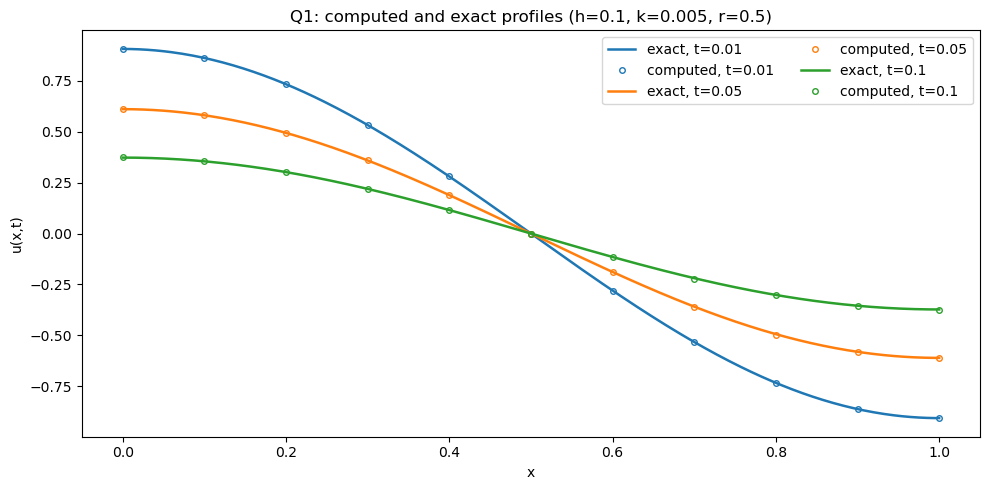

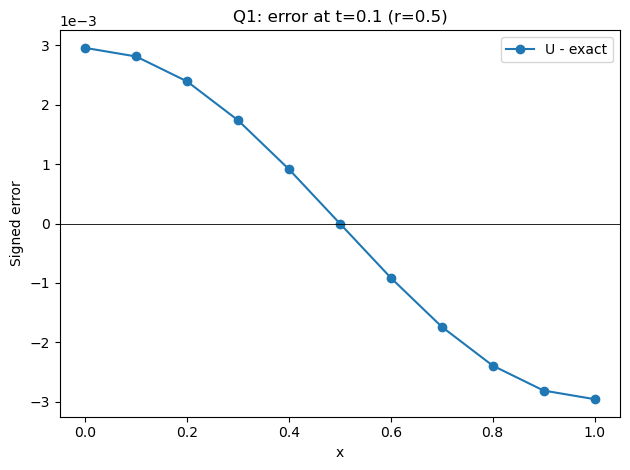

   t   r     max error
0.01 0.5 0.00071561015
0.05 0.5  0.0024147933
 0.1 0.5  0.0029542843
Q1 discrete-mode check: maximum difference = 1.277e-15


In [1]:
# Q1

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


def print_table(frame):
    print(frame.to_string(index=False, float_format=lambda value: f"{value:.8g}"))


def grid_1d(h):
    N = int(round(1.0 / h))
    if N < 2 or not np.isclose(N * h, 1.0):
        raise ValueError('h must divide [0, 1] into at least two intervals.')
    return np.linspace(0.0, 1.0, N + 1)

def time_grid(T, k):
    M = int(round(T / k))
    if M < 1 or not np.isclose(M * k, T):
        raise ValueError('k must divide T; no unreported shortened time step is used.')
    return np.linspace(0.0, T, M + 1)

def second_difference(h, alpha=0.0):
    # u_x(0)=g0(t), u_x(1)+alpha*u(1)=g1(t).
    size = len(grid_1d(h))
    lower = np.ones(size - 1) / h**2
    diagonal = -2.0 * np.ones(size) / h**2
    upper = np.ones(size - 1) / h**2
    upper[0] = 2.0 / h**2
    lower[-1] = 2.0 / h**2
    diagonal[-1] -= 2.0 * alpha / h
    return lower, diagonal, upper

def boundary_source(size, h, g0, g1):
    b = np.zeros(size)
    b[0], b[-1] = -2.0 * g0 / h, 2.0 * g1 / h
    return b


def tri_apply(operator, values):
    # Operate on axis 0; other axes represent independent right-hand sides.
    lower, diagonal, upper = operator
    scale = (-1,) + (1,) * (values.ndim - 1)
    result = diagonal.reshape(scale) * values
    result[1:] += lower.reshape(scale) * values[:-1]
    result[:-1] += upper.reshape(scale) * values[1:]
    return result

class ThomasFactor:
    # Factor once; reuse for all time steps and all line solves.
    def __init__(self, lower, diagonal, upper):
        self.lower = np.asarray(lower, dtype=float).copy()
        self.pivot = np.asarray(diagonal, dtype=float).copy()
        self.upper_ratio = np.zeros(len(diagonal) - 1)
        for i in range(len(diagonal) - 1):
            if abs(self.pivot[i]) < 1e-14:
                raise ArithmeticError('Zero pivot in Thomas algorithm.')
            self.upper_ratio[i] = upper[i] / self.pivot[i]
            self.pivot[i + 1] -= self.lower[i] * self.upper_ratio[i]
        if abs(self.pivot[-1]) < 1e-14:
            raise ArithmeticError('Zero final pivot in Thomas algorithm.')

    def solve(self, rhs):
        answer = np.array(rhs, dtype=float, copy=True)
        answer[0] /= self.pivot[0]
        for i in range(1, len(self.pivot)):
            answer[i] = (answer[i] - self.lower[i - 1] * answer[i - 1]) / self.pivot[i]
        for i in range(len(self.pivot) - 2, -1, -1):
            answer[i] -= self.upper_ratio[i] * answer[i + 1]
        return answer

def implicit_factor(operator, a):
    lower, diagonal, upper = operator
    return ThomasFactor(-a * lower, 1.0 - a * diagonal, -a * upper)


def cn_heat(h, k, T, initial, g0, g1, alpha=0.0):
    x, times = grid_1d(h), time_grid(T, k)
    L = second_difference(h, alpha)
    factor = implicit_factor(L, k / 2.0)
    U = np.empty((len(times), len(x)))
    U[0] = initial(x)
    for n in range(len(times) - 1):
        bn = boundary_source(len(x), h, g0(times[n]), g1(times[n]))
        bnext = boundary_source(len(x), h, g0(times[n + 1]), g1(times[n + 1]))
        rhs = U[n] + (k / 2.0) * (tri_apply(L, U[n]) + bn + bnext)
        U[n + 1] = factor.solve(rhs)
    return x, times, U


def time_index(times, requested):
    j = int(np.argmin(np.abs(times - requested)))
    if not np.isclose(times[j], requested, atol=1e-12, rtol=0):
        raise ValueError('Requested time is not on the time grid.')
    return j


def value_table(x, numerical, exact_values):
    error = numerical - exact_values
    return pd.DataFrame({'x': x, 'computed U': numerical,
                         'exact u': exact_values, 'signed error': error,
                         'absolute error': np.abs(error)})


def show_1d_tables(x, times, U, exact, requested, h, k):
    for t in requested:
        j = time_index(times, t)
        print(f't = {t:g}; h = {h:g}, k = {k:g}, r = {k/h**2:g}')
        print_table(value_table(x, U[j], exact(x, t)))


def profile_plot(x, times, U, exact, requested, title):
    fig, ax = plt.subplots(figsize=(10, 5))
    for color, t in zip(['tab:blue', 'tab:orange', 'tab:green'], requested):
        j = time_index(times, t)
        xf = np.linspace(0, 1, 401)
        ax.plot(xf, exact(xf, t), color=color, lw=1.8, label=f'exact, t={t:g}')
        ax.plot(x, U[j], 'o', color=color, ms=4, mfc='none', label=f'computed, t={t:g}')
    ax.set(xlabel='x', ylabel='u(x,t)', title=title)
    ax.legend(ncol=2)
    fig.tight_layout()
    plt.show()


h1, k1 = 0.1, 0.005
exact1 = lambda x, t: np.exp(-np.pi**2 * t) * np.cos(np.pi * x)
x1, times1, U1 = cn_heat(h1, k1, 0.1, lambda x: np.cos(np.pi*x),
                         lambda t: 0.0, lambda t: 0.0)
show_1d_tables(x1, times1, U1, exact1, [0.01, 0.05, 0.1], h1, k1)
profile_plot(x1, times1, U1, exact1, [0.01, 0.05, 0.1],
             'Q1: computed and exact profiles (h=0.1, k=0.005, r=0.5)')
fig, ax = plt.subplots()
ax.plot(x1, U1[-1] - exact1(x1, 0.1), 'o-', label='U - exact')
ax.axhline(0, color='black', lw=0.6)
ax.set(xlabel='x', ylabel='Signed error', title='Q1: error at t=0.1 (r=0.5)')
ax.ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
ax.legend()
fig.tight_layout()
plt.show()
q1_summary = pd.DataFrame([{'t': t, 'r': k1/h1**2,
                            'max error': np.max(np.abs(U1[time_index(times1,t)] - exact1(x1,t)))}
                           for t in [0.01, 0.05, 0.1]])
print_table(q1_summary)


lambda_h1 = 4/h1**2 * np.sin(np.pi*h1/2)**2
q1 = (1-k1*lambda_h1/2)/(1+k1*lambda_h1/2)
modal1 = q1**np.arange(len(times1))[:, None] * np.cos(np.pi*x1)[None, :]
q1_modal_residual = np.max(np.abs(U1 - modal1))
assert q1_modal_residual < 1e-12
print(f'Q1 discrete-mode check: maximum difference = {q1_modal_residual:.3e}')

t = 0.1; h = 0.05, k = 0.05, r = 20
   x     computed U     exact u   signed error  absolute error
   0 -0.00012232167           0 -0.00012232167   0.00012232167
0.05    0.045105276 0.045223022 -0.00011774632   0.00011774632
 0.1    0.090226551 0.090333011 -0.00010645983   0.00010645983
0.15     0.13512487  0.13521721 -9.2346721e-05   9.2346721e-05
 0.2     0.17968578  0.17976344 -7.7661564e-05   7.7661564e-05
0.25     0.22379674  0.22386036 -6.3621059e-05   6.3621059e-05
 0.3     0.26734695  0.26739774 -5.0794209e-05   5.0794209e-05
0.35     0.31022741  0.31026677 -3.9356533e-05   3.9356533e-05
 0.4     0.35233103  0.35236029 -2.9253432e-05   2.9253432e-05
0.45     0.39355279  0.39357309 -2.0303643e-05   2.0303643e-05
 0.5      0.4337899  0.43380217 -1.2264022e-05   1.2264022e-05
0.55     0.47294209  0.47294696 -4.8704036e-06   4.8704036e-06
 0.6     0.51091177  0.51090964  2.1348294e-06   2.1348294e-06
0.65     0.54760429   0.5475953  8.9803404e-06   8.9803404e-06
 0.7     0.58292811

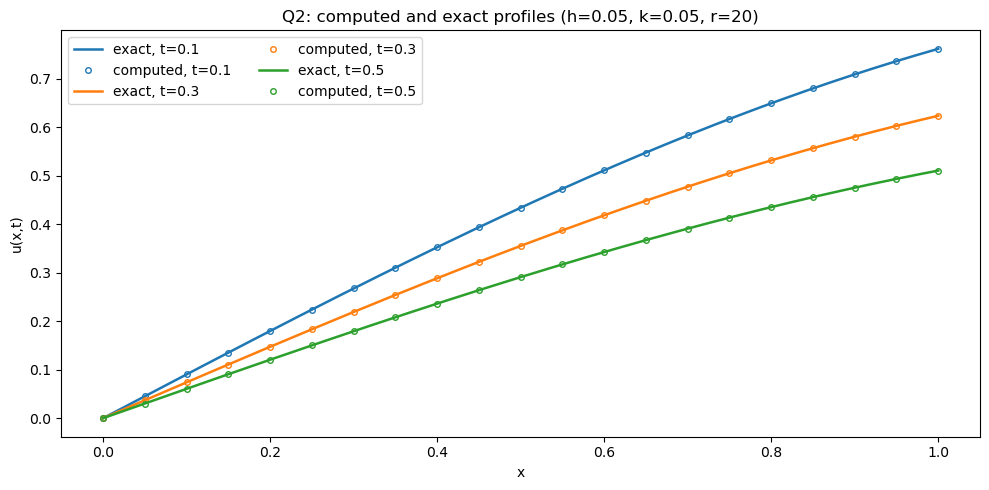

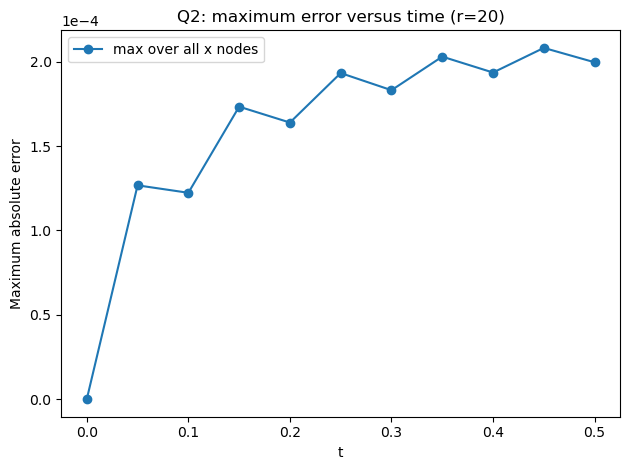

   t  r     max error
   0 20             0
0.05 20 0.00012673746
 0.1 20 0.00012232167
0.15 20 0.00017336249
 0.2 20 0.00016395503
0.25 20 0.00019328042
 0.3 20 0.00018312645
0.35 20 0.00020301971
 0.4 20 0.00019359161
0.45 20 0.00020819936
 0.5 20 0.00019966817


In [2]:
# Q2

def print_table(frame):
    print(frame.to_string(index=False, float_format=lambda value: f"{value:.8g}"))


def grid_1d(h):
    N = int(round(1.0 / h))
    if N < 2 or not np.isclose(N * h, 1.0):
        raise ValueError('h must divide [0, 1] into at least two intervals.')
    return np.linspace(0.0, 1.0, N + 1)

def time_grid(T, k):
    M = int(round(T / k))
    if M < 1 or not np.isclose(M * k, T):
        raise ValueError('k must divide T; no unreported shortened time step is used.')
    return np.linspace(0.0, T, M + 1)

def second_difference(h, alpha=0.0):
    # u_x(0)=g0(t), u_x(1)+alpha*u(1)=g1(t).
    size = len(grid_1d(h))
    lower = np.ones(size - 1) / h**2
    diagonal = -2.0 * np.ones(size) / h**2
    upper = np.ones(size - 1) / h**2
    upper[0] = 2.0 / h**2
    lower[-1] = 2.0 / h**2
    diagonal[-1] -= 2.0 * alpha / h
    return lower, diagonal, upper

def boundary_source(size, h, g0, g1):
    b = np.zeros(size)
    b[0], b[-1] = -2.0 * g0 / h, 2.0 * g1 / h
    return b


def tri_apply(operator, values):
    # Operate on axis 0; other axes represent independent right-hand sides.
    lower, diagonal, upper = operator
    scale = (-1,) + (1,) * (values.ndim - 1)
    result = diagonal.reshape(scale) * values
    result[1:] += lower.reshape(scale) * values[:-1]
    result[:-1] += upper.reshape(scale) * values[1:]
    return result

class ThomasFactor:
    # Factor once; reuse for all time steps and all line solves.
    def __init__(self, lower, diagonal, upper):
        self.lower = np.asarray(lower, dtype=float).copy()
        self.pivot = np.asarray(diagonal, dtype=float).copy()
        self.upper_ratio = np.zeros(len(diagonal) - 1)
        for i in range(len(diagonal) - 1):
            if abs(self.pivot[i]) < 1e-14:
                raise ArithmeticError('Zero pivot in Thomas algorithm.')
            self.upper_ratio[i] = upper[i] / self.pivot[i]
            self.pivot[i + 1] -= self.lower[i] * self.upper_ratio[i]
        if abs(self.pivot[-1]) < 1e-14:
            raise ArithmeticError('Zero final pivot in Thomas algorithm.')

    def solve(self, rhs):
        answer = np.array(rhs, dtype=float, copy=True)
        answer[0] /= self.pivot[0]
        for i in range(1, len(self.pivot)):
            answer[i] = (answer[i] - self.lower[i - 1] * answer[i - 1]) / self.pivot[i]
        for i in range(len(self.pivot) - 2, -1, -1):
            answer[i] -= self.upper_ratio[i] * answer[i + 1]
        return answer

def implicit_factor(operator, a):
    lower, diagonal, upper = operator
    return ThomasFactor(-a * lower, 1.0 - a * diagonal, -a * upper)


def cn_heat(h, k, T, initial, g0, g1, alpha=0.0):
    x, times = grid_1d(h), time_grid(T, k)
    L = second_difference(h, alpha)
    factor = implicit_factor(L, k / 2.0)
    U = np.empty((len(times), len(x)))
    U[0] = initial(x)
    for n in range(len(times) - 1):
        bn = boundary_source(len(x), h, g0(times[n]), g1(times[n]))
        bnext = boundary_source(len(x), h, g0(times[n + 1]), g1(times[n + 1]))
        rhs = U[n] + (k / 2.0) * (tri_apply(L, U[n]) + bn + bnext)
        U[n + 1] = factor.solve(rhs)
    return x, times, U

def mixed_cn(h, k, T=0.5):
    return cn_heat(h, k, T, np.sin,
                   lambda t: np.exp(-t),
                   lambda t: (np.cos(1.0) + np.sin(1.0)) * np.exp(-t),
                   alpha=1.0)


def time_index(times, requested):
    j = int(np.argmin(np.abs(times - requested)))
    if not np.isclose(times[j], requested, atol=1e-12, rtol=0):
        raise ValueError('Requested time is not on the time grid.')
    return j


def value_table(x, numerical, exact_values):
    error = numerical - exact_values
    return pd.DataFrame({'x': x, 'computed U': numerical,
                         'exact u': exact_values, 'signed error': error,
                         'absolute error': np.abs(error)})


def show_1d_tables(x, times, U, exact, requested, h, k):
    for t in requested:
        j = time_index(times, t)
        print(f't = {t:g}; h = {h:g}, k = {k:g}, r = {k/h**2:g}')
        print_table(value_table(x, U[j], exact(x, t)))


def profile_plot(x, times, U, exact, requested, title):
    fig, ax = plt.subplots(figsize=(10, 5))
    for color, t in zip(['tab:blue', 'tab:orange', 'tab:green'], requested):
        j = time_index(times, t)
        xf = np.linspace(0, 1, 401)
        ax.plot(xf, exact(xf, t), color=color, lw=1.8, label=f'exact, t={t:g}')
        ax.plot(x, U[j], 'o', color=color, ms=4, mfc='none', label=f'computed, t={t:g}')
    ax.set(xlabel='x', ylabel='u(x,t)', title=title)
    ax.legend(ncol=2)
    fig.tight_layout()
    plt.show()


h2, k2 = 0.05, 0.05
exact2 = lambda x, t: np.exp(-t) * np.sin(x)
x2, times2, U2 = mixed_cn(h2, k2)
show_1d_tables(x2, times2, U2, exact2, [0.1, 0.3, 0.5], h2, k2)
profile_plot(x2, times2, U2, exact2, [0.1, 0.3, 0.5],
             'Q2: computed and exact profiles (h=0.05, k=0.05, r=20)')
error2 = np.max(np.abs(U2 - np.exp(-times2[:,None]) * np.sin(x2)[None,:]), axis=1)
fig, ax = plt.subplots()
ax.plot(times2, error2, 'o-', label='max over all x nodes')
ax.set(xlabel='t', ylabel='Maximum absolute error',
       title='Q2: maximum error versus time (r=20)')
ax.ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
ax.legend()
fig.tight_layout()
plt.show()
print_table(pd.DataFrame({'t': times2, 'r': k2/h2**2, 'max error': error2}))

     h      k  r     max error  previous error / error  observed p
   0.1    0.1 10 0.00085979403                     NaN         NaN
  0.05   0.05 20 0.00019966817               4.3061147   2.1063867
 0.025  0.025 40 5.0534319e-05               3.9511399   1.9822689
0.0125 0.0125 80 1.2711564e-05               3.9754603   1.9911219
Finest-grid observed coupled order: 1.9911
Additional spatial study: errors at t=0.5
     h          k  r     max error  previous error / error  observed p
   0.1       0.01  1 0.00070830873                     NaN         NaN
  0.05     0.0025  1 0.00017685639               4.0049937      2.0018
 0.025   0.000625  1 4.4200349e-05               4.0012442   2.0004487
0.0125 0.00015625  1 1.1049229e-05               4.0003108   2.0001121
Additional temporal self-convergence at t=0.5
   h  k (coarse)  k (fine)  r (coarse)  r (fine)  difference D(k)  previous D / D  observed p
0.05        0.05     0.025          20        10    2.2828466e-05             NaN    

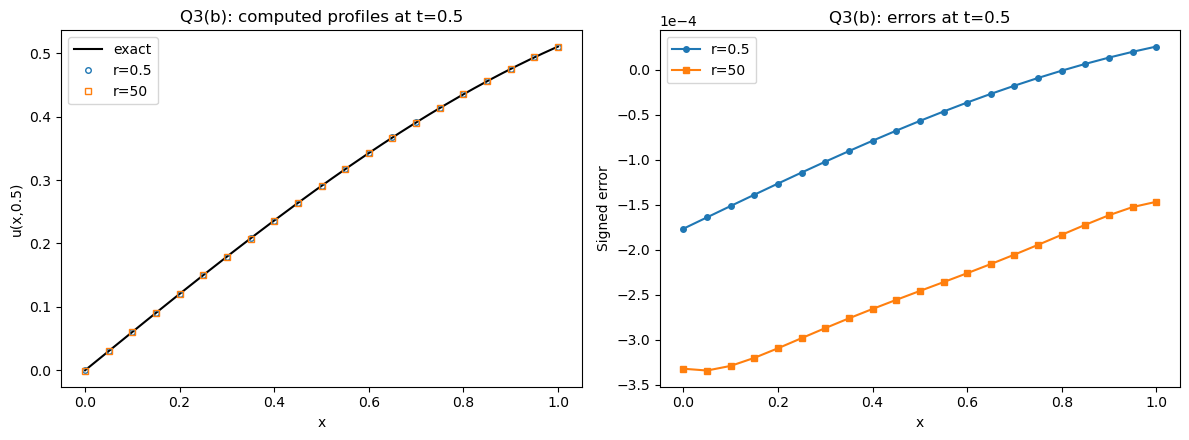

In [3]:
# Q3

def print_table(frame):
    print(frame.to_string(index=False, float_format=lambda value: f"{value:.8g}"))


def grid_1d(h):
    N = int(round(1.0 / h))
    if N < 2 or not np.isclose(N * h, 1.0):
        raise ValueError('h must divide [0, 1] into at least two intervals.')
    return np.linspace(0.0, 1.0, N + 1)

def time_grid(T, k):
    M = int(round(T / k))
    if M < 1 or not np.isclose(M * k, T):
        raise ValueError('k must divide T; no unreported shortened time step is used.')
    return np.linspace(0.0, T, M + 1)

def second_difference(h, alpha=0.0):
    # u_x(0)=g0(t), u_x(1)+alpha*u(1)=g1(t).
    size = len(grid_1d(h))
    lower = np.ones(size - 1) / h**2
    diagonal = -2.0 * np.ones(size) / h**2
    upper = np.ones(size - 1) / h**2
    upper[0] = 2.0 / h**2
    lower[-1] = 2.0 / h**2
    diagonal[-1] -= 2.0 * alpha / h
    return lower, diagonal, upper

def boundary_source(size, h, g0, g1):
    b = np.zeros(size)
    b[0], b[-1] = -2.0 * g0 / h, 2.0 * g1 / h
    return b


def tri_apply(operator, values):
    # Operate on axis 0; other axes represent independent right-hand sides.
    lower, diagonal, upper = operator
    scale = (-1,) + (1,) * (values.ndim - 1)
    result = diagonal.reshape(scale) * values
    result[1:] += lower.reshape(scale) * values[:-1]
    result[:-1] += upper.reshape(scale) * values[1:]
    return result

class ThomasFactor:
    # Factor once; reuse for all time steps and all line solves.
    def __init__(self, lower, diagonal, upper):
        self.lower = np.asarray(lower, dtype=float).copy()
        self.pivot = np.asarray(diagonal, dtype=float).copy()
        self.upper_ratio = np.zeros(len(diagonal) - 1)
        for i in range(len(diagonal) - 1):
            if abs(self.pivot[i]) < 1e-14:
                raise ArithmeticError('Zero pivot in Thomas algorithm.')
            self.upper_ratio[i] = upper[i] / self.pivot[i]
            self.pivot[i + 1] -= self.lower[i] * self.upper_ratio[i]
        if abs(self.pivot[-1]) < 1e-14:
            raise ArithmeticError('Zero final pivot in Thomas algorithm.')

    def solve(self, rhs):
        answer = np.array(rhs, dtype=float, copy=True)
        answer[0] /= self.pivot[0]
        for i in range(1, len(self.pivot)):
            answer[i] = (answer[i] - self.lower[i - 1] * answer[i - 1]) / self.pivot[i]
        for i in range(len(self.pivot) - 2, -1, -1):
            answer[i] -= self.upper_ratio[i] * answer[i + 1]
        return answer

def implicit_factor(operator, a):
    lower, diagonal, upper = operator
    return ThomasFactor(-a * lower, 1.0 - a * diagonal, -a * upper)


def cn_heat(h, k, T, initial, g0, g1, alpha=0.0):
    x, times = grid_1d(h), time_grid(T, k)
    L = second_difference(h, alpha)
    factor = implicit_factor(L, k / 2.0)
    U = np.empty((len(times), len(x)))
    U[0] = initial(x)
    for n in range(len(times) - 1):
        bn = boundary_source(len(x), h, g0(times[n]), g1(times[n]))
        bnext = boundary_source(len(x), h, g0(times[n + 1]), g1(times[n + 1]))
        rhs = U[n] + (k / 2.0) * (tri_apply(L, U[n]) + bn + bnext)
        U[n + 1] = factor.solve(rhs)
    return x, times, U

def mixed_cn(h, k, T=0.5):
    return cn_heat(h, k, T, np.sin,
                   lambda t: np.exp(-t),
                   lambda t: (np.cos(1.0) + np.sin(1.0)) * np.exp(-t),
                   alpha=1.0)


def convergence_table(rows):
    table = pd.DataFrame(rows)
    table['previous error / error'] = table['max error'].shift(1) / table['max error']
    table['observed p'] = np.log2(table['previous error / error'])
    return table


exact2 = lambda x, t: np.exp(-t) * np.sin(x)


# 3(a): k = h and separate spatial and temporal refinement
rows3a = []
for h in [1/10, 1/20, 1/40, 1/80]:
    k = h
    x, times, U = mixed_cn(h, k)
    rows3a.append({'h': h, 'k': k, 'r': k/h**2,
                   'max error': np.max(np.abs(U[-1] - exact2(x, 0.5)))})
table3a = convergence_table(rows3a)
print_table(table3a)
print(f'Finest-grid observed coupled order: {table3a["observed p"].iloc[-1]:.4f}')


space_rows = []
for h in [0.1, 0.05, 0.025, 0.0125]:
    k = h*h
    x, times, U = mixed_cn(h, k)
    space_rows.append({'h': h, 'k': k, 'r': k/h**2,
                       'max error': np.max(np.abs(U[-1] - exact2(x, 0.5)))})
space_table = convergence_table(space_rows)
print('Additional spatial study: errors at t=0.5')
print_table(space_table)

h_time = 0.05
ks = [0.05, 0.025, 0.0125, 0.00625, 0.003125]
time_solutions = [mixed_cn(h_time, k)[2][-1] for k in ks]
time_rows = []
for i, k in enumerate(ks[:-1]):
    time_rows.append({'h': h_time, 'k (coarse)': k, 'k (fine)': k/2,
                      'r (coarse)': k/h_time**2, 'r (fine)': (k/2)/h_time**2,
                      'difference D(k)': np.max(np.abs(time_solutions[i] - time_solutions[i+1]))})
time_table = pd.DataFrame(time_rows)
time_table['previous D / D'] = time_table['difference D(k)'].shift(1)/time_table['difference D(k)']
time_table['observed p'] = np.log2(time_table['previous D / D'])
print('Additional temporal self-convergence at t=0.5')
print_table(time_table)
print('Observed spatial order:', round(space_table['observed p'].iloc[-1], 4))
print('Observed temporal order:', round(time_table['observed p'].iloc[-1], 4))


# 3(b): fixed h, varying mesh ratio
rows3b, profiles3b = [], {}
h3b = 1/20
for r in [0.5, 1, 5, 10, 50]:
    k = r*h3b**2
    x, times, U = mixed_cn(h3b, k)
    rows3b.append({'h': h3b, 'r': r, 'k': k, 'time steps': len(times)-1,
                   'max error': np.max(np.abs(U[-1] - exact2(x, 0.5)))})
    profiles3b[r] = U[-1].copy()
table3b = pd.DataFrame(rows3b)
print_table(table3b)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
xf = np.linspace(0, 1, 401)
axes[0].plot(xf, exact2(xf, 0.5), 'k-', label='exact')
for r, marker in [(0.5, 'o'), (50, 's')]:
    axes[0].plot(x, profiles3b[r], marker, ms=4, mfc='none', label=f'r={r:g}')
    axes[1].plot(x, profiles3b[r]-exact2(x, 0.5), marker+'-', ms=4, label=f'r={r:g}')
axes[0].set(xlabel='x', ylabel='u(x,0.5)', title='Q3(b): computed profiles at t=0.5')
axes[1].set(xlabel='x', ylabel='Signed error', title='Q3(b): errors at t=0.5')
axes[1].ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
for ax in axes:
    ax.legend()
fig.tight_layout()
plt.show()


# At fixed h, raising r raises the time step. The largest r gives greater temporal error.

Q4 coarse: t=0.01, y=0.5; h=0.05, k=0.001, r=0.4
   x     computed U        exact u   signed error  absolute error
   0 -8.6736174e-17  5.0263712e-17 -1.3699989e-16   1.3699989e-16
0.05 -8.3266727e-17  4.9644883e-17 -1.3291161e-16   1.3291161e-16
 0.1 -8.6736174e-17  4.7803631e-17  -1.345398e-16    1.345398e-16
0.15  -7.979728e-17  4.4785296e-17 -1.2458258e-16   1.2458258e-16
 0.2 -6.5919492e-17  4.0664198e-17 -1.0658369e-16   1.0658369e-16
0.25 -5.0306981e-17  3.5541812e-17 -8.5848793e-17   8.5848793e-17
 0.3 -4.6837534e-17  2.9544269e-17 -7.6381803e-17   7.6381803e-17
0.35  -3.989864e-17  2.2819248e-17 -6.2717888e-17   6.2717888e-17
 0.4 -2.9490299e-17  1.5532341e-17  -4.502264e-17    4.502264e-17
0.45  -1.517883e-17   7.862977e-18 -2.3041807e-17   2.3041807e-17
 0.5 -1.5501891e-19  3.0777647e-33 -1.5501891e-19   1.5501891e-19
0.55  1.3877788e-17  -7.862977e-18  2.1740765e-17   2.1740765e-17
 0.6  2.7755576e-17 -1.5532341e-17  4.3287917e-17   4.3287917e-17
0.65  3.8163916e-17 -2.2819

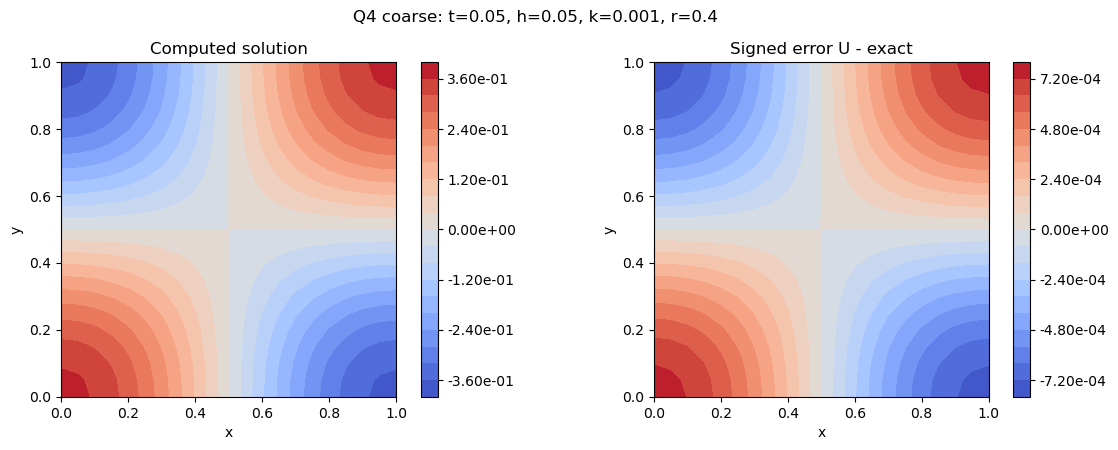

Q4 fine: t=0.01, y=0.5; h=0.025, k=0.00025, r=0.4
    x     computed U        exact u   signed error  absolute error
    0 -2.2551405e-17  5.0263712e-17 -7.2815118e-17   7.2815118e-17
0.025 -2.4286129e-17  5.0108766e-17 -7.4394895e-17   7.4394895e-17
 0.05 -3.2959746e-17  4.9644883e-17 -8.2604629e-17   8.2604629e-17
0.075 -3.6429193e-17  4.8874922e-17 -8.5304115e-17   8.5304115e-17
  0.1 -4.3368087e-17  4.7803631e-17 -9.1171718e-17   9.1171718e-17
0.125 -4.3368087e-17  4.6437615e-17 -8.9805702e-17   8.9805702e-17
 0.15  -3.989864e-17  4.4785296e-17 -8.4683936e-17   8.4683936e-17
0.175 -3.8163916e-17   4.285686e-17 -8.1020776e-17   8.1020776e-17
  0.2 -3.7296555e-17  4.0664198e-17 -7.7960752e-17   7.7960752e-17
0.225 -3.6429193e-17  3.8220827e-17  -7.465002e-17    7.465002e-17
 0.25 -2.9490299e-17  3.5541812e-17 -6.5032111e-17   6.5032111e-17
0.275 -2.1684043e-17   3.264367e-17 -5.4327713e-17   5.4327713e-17
  0.3 -1.2143064e-17  2.9544269e-17 -4.1687333e-17   4.1687333e-17
0.325 -8.673

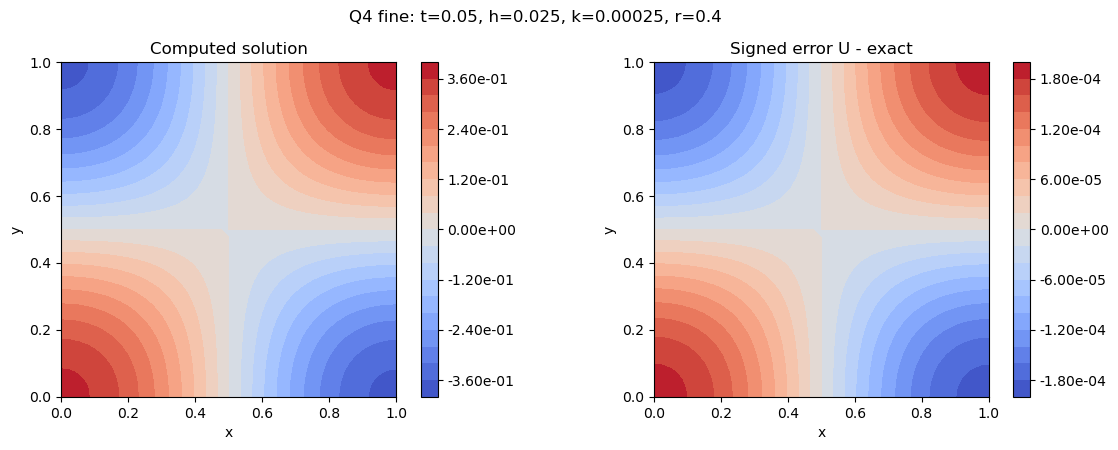

t=0.01: coarse/fine error ratio = 3.986367; observed order in h = 1.995075
t=0.05: coarse/fine error ratio = 3.988781; observed order in h = 1.995948
   t   mesh     h       k   r  full-grid max error  mode check difference
0.01 coarse  0.05   0.001 0.4        0.00033165284          9.9920072e-16
0.01   fine 0.025 0.00025 0.4        8.3196758e-05          9.7699626e-15
0.05 coarse  0.05   0.001 0.4        0.00075352816          2.6645353e-15
0.05   fine 0.025 0.00025 0.4        0.00018891188          2.2759572e-14


In [4]:
# Q4

def print_table(frame):
    print(frame.to_string(index=False, float_format=lambda value: f"{value:.8g}"))


def grid_1d(h):
    N = int(round(1.0 / h))
    if N < 2 or not np.isclose(N * h, 1.0):
        raise ValueError('h must divide [0, 1] into at least two intervals.')
    return np.linspace(0.0, 1.0, N + 1)

def time_grid(T, k):
    M = int(round(T / k))
    if M < 1 or not np.isclose(M * k, T):
        raise ValueError('k must divide T; no unreported shortened time step is used.')
    return np.linspace(0.0, T, M + 1)

def second_difference(h, alpha=0.0):
    # u_x(0)=g0(t), u_x(1)+alpha*u(1)=g1(t).
    size = len(grid_1d(h))
    lower = np.ones(size - 1) / h**2
    diagonal = -2.0 * np.ones(size) / h**2
    upper = np.ones(size - 1) / h**2
    upper[0] = 2.0 / h**2
    lower[-1] = 2.0 / h**2
    diagonal[-1] -= 2.0 * alpha / h
    return lower, diagonal, upper



def tri_apply(operator, values):
    # Operate on axis 0; other axes represent independent right-hand sides.
    lower, diagonal, upper = operator
    scale = (-1,) + (1,) * (values.ndim - 1)
    result = diagonal.reshape(scale) * values
    result[1:] += lower.reshape(scale) * values[:-1]
    result[:-1] += upper.reshape(scale) * values[1:]
    return result

class ThomasFactor:
    # Factor once; reuse for all time steps and all line solves.
    def __init__(self, lower, diagonal, upper):
        self.lower = np.asarray(lower, dtype=float).copy()
        self.pivot = np.asarray(diagonal, dtype=float).copy()
        self.upper_ratio = np.zeros(len(diagonal) - 1)
        for i in range(len(diagonal) - 1):
            if abs(self.pivot[i]) < 1e-14:
                raise ArithmeticError('Zero pivot in Thomas algorithm.')
            self.upper_ratio[i] = upper[i] / self.pivot[i]
            self.pivot[i + 1] -= self.lower[i] * self.upper_ratio[i]
        if abs(self.pivot[-1]) < 1e-14:
            raise ArithmeticError('Zero final pivot in Thomas algorithm.')

    def solve(self, rhs):
        answer = np.array(rhs, dtype=float, copy=True)
        answer[0] /= self.pivot[0]
        for i in range(1, len(self.pivot)):
            answer[i] = (answer[i] - self.lower[i - 1] * answer[i - 1]) / self.pivot[i]
        for i in range(len(self.pivot) - 2, -1, -1):
            answer[i] -= self.upper_ratio[i] * answer[i + 1]
        return answer

def implicit_factor(operator, a):
    lower, diagonal, upper = operator
    return ThomasFactor(-a * lower, 1.0 - a * diagonal, -a * upper)


def pr_adi(h, k, T, initial, exact, alpha_x=0.0, x_boundary=None,
           save_times=()):
    # U[i,j] = U(x_i,y_j); y boundaries are homogeneous Neumann.
    x, y, times = grid_1d(h), grid_1d(h), time_grid(T, k)
    X, Y = np.meshgrid(x, y, indexing='ij')
    Lx, Ly = second_difference(h, alpha_x), second_difference(h)
    a = k / 2.0
    solve_x, solve_y = implicit_factor(Lx, a), implicit_factor(Ly, a)
    U = initial(X, Y)
    save_steps = {int(round(t / k)) for t in save_times}
    for t in save_times:
        if not np.isclose(round(t / k) * k, t) or not (0 <= t <= T):
            raise ValueError('Each snapshot must lie on the time grid.')
    snapshots = {0: U.copy()} if 0 in save_steps else {}
    errors = np.empty(len(times))
    errors[0] = np.max(np.abs(U - exact(X, Y, 0.0)))
    for n in range(len(times) - 1):
        midpoint = (times[n] + times[n + 1]) / 2.0
        B = np.zeros_like(U)
        if x_boundary is not None:
            g0, g1 = x_boundary(y, midpoint)
            B[0, :], B[-1, :] = -2.0 * g0 / h, 2.0 * g1 / h
        # Stage 1: implicit in x, explicit in y.
        rhs_x = U + a * tri_apply(Ly, U.T).T + a * B
        intermediate = solve_x.solve(rhs_x)
        # Stage 2: explicit in x, implicit in y.
        rhs_y = intermediate + a * tri_apply(Lx, intermediate) + a * B
        U = solve_y.solve(rhs_y.T).T
        errors[n + 1] = np.max(np.abs(U - exact(X, Y, times[n + 1])))
        if n + 1 in save_steps:
            snapshots[n + 1] = U.copy()
    return x, y, times, U, snapshots, errors


def time_index(times, requested):
    j = int(np.argmin(np.abs(times - requested)))
    if not np.isclose(times[j], requested, atol=1e-12, rtol=0):
        raise ValueError('Requested time is not on the time grid.')
    return j


def value_table(x, numerical, exact_values):
    error = numerical - exact_values
    return pd.DataFrame({'x': x, 'computed U': numerical,
                         'exact u': exact_values, 'signed error': error,
                         'absolute error': np.abs(error)})


def show_adi_lines(result, exact, requested_times, requested_y, h, k, label):
    x, y, times, final, snapshots, errors = result
    for t in requested_times:
        n = time_index(times, t)
        for y_value in requested_y:
            j = int(round(y_value/h))
            if not np.isclose(y[j], y_value):
                raise ValueError('Requested line is not on the spatial grid.')
            print(f'{label}: t={t:g}, y={y_value:g}; '
                             f'h={h:g}, k={k:g}, r={k/h**2:g}')
            print_table(value_table(x, snapshots[n][:, j], exact(x, y[j], t)))

def contour_solution_error(result, exact, T, title):
    x, y, times, final, snapshots, errors = result
    X, Y = np.meshgrid(x, y, indexing='ij')
    signed_error = final - exact(X, Y, T)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for ax, values, label in zip(axes, [final, signed_error],
                                ['Computed solution', 'Signed error U - exact']):
        contour = ax.contourf(X, Y, values, levels=21, cmap='coolwarm')
        ax.set(xlabel='x', ylabel='y', title=label, aspect='equal')
        ax.grid(False)
        fig.colorbar(contour, ax=ax, format='%.2e')
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


exact4 = lambda X,Y,t: np.exp(-2*np.pi**2*t)*np.cos(np.pi*X)*np.cos(np.pi*Y)


q4_results = {}
for h, k, name in [(0.05, 0.001, 'coarse'), (0.025, 0.00025, 'fine')]:
    result = pr_adi(h, k, 0.05,
                    lambda X,Y: np.cos(np.pi*X)*np.cos(np.pi*Y),
                    exact4, save_times=[0.01, 0.05])
    q4_results[name] = result
    show_adi_lines(result, exact4, [0.01, 0.05], [0.5], h, k, f'Q4 {name}')
    contour_solution_error(result, exact4, 0.05,
                            f'Q4 {name}: t=0.05, h={h:g}, k={k:g}, r={k/h**2:g}')


q4_rows, q4_mode_residuals = [], []
for T in [0.01, 0.05]:
    errors_at_T = []
    for h, k, name in [(0.05, 0.001, 'coarse'), (0.025, 0.00025, 'fine')]:
        x, y, times, final, snaps, errs = q4_results[name]
        n = time_index(times, T)
        X, Y = np.meshgrid(x, y, indexing='ij')
        E = np.max(np.abs(snaps[n] - exact4(X, Y, T)))
        errors_at_T.append(E)
        lam = 4/h**2 * np.sin(np.pi*h/2)**2
        q = (1-k*lam/2)/(1+k*lam/2)
        mode_residual = np.max(np.abs(snaps[n] - q**(2*n)*np.cos(np.pi*X)*np.cos(np.pi*Y)))
        q4_mode_residuals.append(mode_residual)
        q4_rows.append({'t': T, 'mesh': name, 'h': h, 'k': k, 'r': k/h**2,
                        'full-grid max error': E,
                        'mode check difference': mode_residual})
    ratio = errors_at_T[0]/errors_at_T[1]
    print(f't={T:g}: coarse/fine error ratio = {ratio:.6f}; observed order in h = {np.log2(ratio):.6f}')
q4_table = pd.DataFrame(q4_rows)
print_table(q4_table)
assert max(q4_mode_residuals) < 2e-12


# With k proportional to h**2, the observed order mainly measures spatial error.

Q5: t=0.05, y=0; h=0.05, k=0.002, r=0.8
   x    computed U     exact u  signed error  absolute error
   0 2.9565075e-05           0 2.9565075e-05   2.9565075e-05
0.05   0.029069956 0.029024087 4.5868473e-05   4.5868473e-05
 0.1   0.058042033  0.05797563  6.640368e-05    6.640368e-05
0.15   0.086872248 0.086782263 8.9985439e-05   8.9985439e-05
 0.2    0.11548762  0.11537199 0.00011563101   0.00011563101
0.25    0.14381588  0.14367334 0.00014254524   0.00014254524
 0.3    0.17178568  0.17161558 0.00017009882   0.00017009882
0.35    0.19932668  0.19912888  0.0001978016    0.0001978016
 0.4    0.22636973  0.22614445 0.00022527259   0.00022527259
0.45      0.252847  0.25259479 0.00025220825   0.00025220825
 0.5    0.27869212  0.27841377 0.00027835029   0.00027835029
0.55    0.30384031  0.30353685 0.00030345361   0.00030345361
 0.6    0.32822851  0.32790126 0.00032725479   0.00032725479
0.65    0.35179552  0.35144608 0.00034944149   0.00034944149
 0.7    0.37448209  0.37411247 0.00036962284 

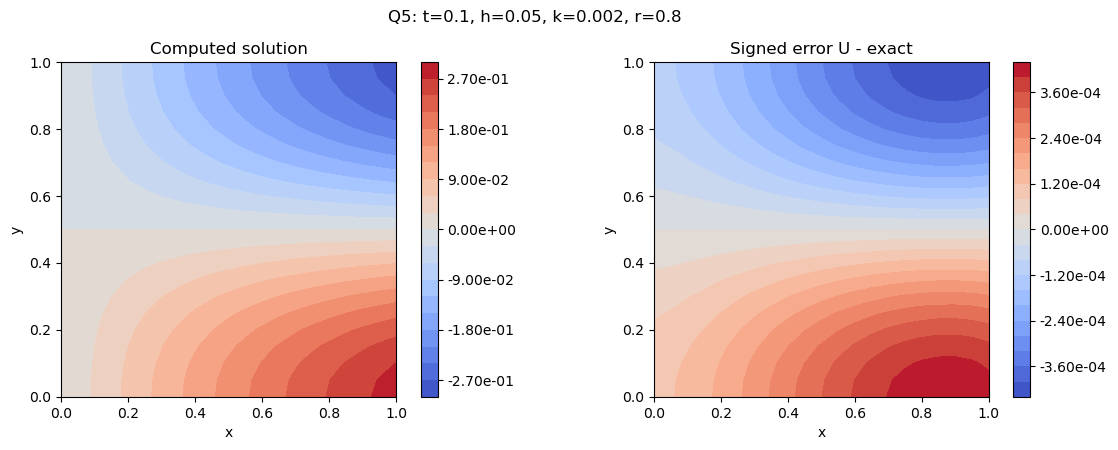

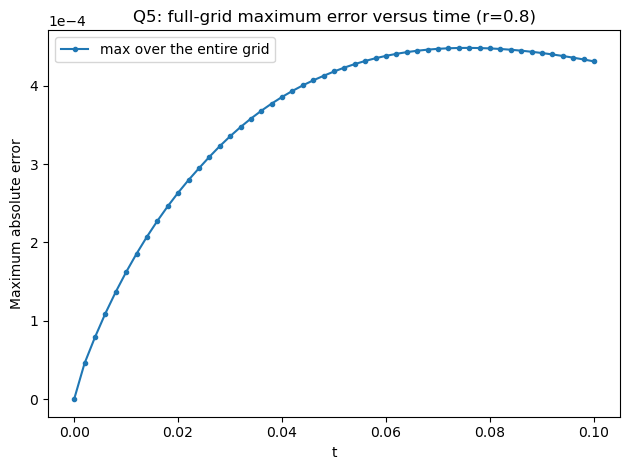

    t   r  full-grid max error
    0 0.8                    0
0.002 0.8        4.5708323e-05
0.004 0.8        7.8939227e-05
0.006 0.8          0.000109322
0.008 0.8        0.00013685093
 0.01 0.8        0.00016219106
0.012 0.8        0.00018560011
0.014 0.8        0.00020729294
0.016 0.8        0.00022742617
0.018 0.8        0.00024612772
 0.02 0.8        0.00026350431
0.022 0.8        0.00027964785
0.024 0.8        0.00029463898
0.026 0.8        0.00030917222
0.028 0.8        0.00032283496
 0.03 0.8        0.00033550411
0.032 0.8        0.00034723457
0.034 0.8        0.00035807722
0.036 0.8        0.00036807937
0.038 0.8        0.00037728521
 0.04 0.8        0.00038573615
0.042 0.8         0.0003934711
0.044 0.8        0.00040052673
0.046 0.8        0.00040693764
0.048 0.8        0.00041273659
 0.05 0.8        0.00041822422
0.052 0.8        0.00042323897
0.054 0.8        0.00042771597
0.056 0.8        0.00043168203
0.058 0.8        0.00043516271
 0.06 0.8         0.0004381824
0.062 0.

In [5]:
# Q5

def print_table(frame):
    print(frame.to_string(index=False, float_format=lambda value: f"{value:.8g}"))


def grid_1d(h):
    N = int(round(1.0 / h))
    if N < 2 or not np.isclose(N * h, 1.0):
        raise ValueError('h must divide [0, 1] into at least two intervals.')
    return np.linspace(0.0, 1.0, N + 1)

def time_grid(T, k):
    M = int(round(T / k))
    if M < 1 or not np.isclose(M * k, T):
        raise ValueError('k must divide T; no unreported shortened time step is used.')
    return np.linspace(0.0, T, M + 1)

def second_difference(h, alpha=0.0):
    # u_x(0)=g0(t), u_x(1)+alpha*u(1)=g1(t).
    size = len(grid_1d(h))
    lower = np.ones(size - 1) / h**2
    diagonal = -2.0 * np.ones(size) / h**2
    upper = np.ones(size - 1) / h**2
    upper[0] = 2.0 / h**2
    lower[-1] = 2.0 / h**2
    diagonal[-1] -= 2.0 * alpha / h
    return lower, diagonal, upper



def tri_apply(operator, values):
    # Operate on axis 0; other axes represent independent right-hand sides.
    lower, diagonal, upper = operator
    scale = (-1,) + (1,) * (values.ndim - 1)
    result = diagonal.reshape(scale) * values
    result[1:] += lower.reshape(scale) * values[:-1]
    result[:-1] += upper.reshape(scale) * values[1:]
    return result

class ThomasFactor:
    # Factor once; reuse for all time steps and all line solves.
    def __init__(self, lower, diagonal, upper):
        self.lower = np.asarray(lower, dtype=float).copy()
        self.pivot = np.asarray(diagonal, dtype=float).copy()
        self.upper_ratio = np.zeros(len(diagonal) - 1)
        for i in range(len(diagonal) - 1):
            if abs(self.pivot[i]) < 1e-14:
                raise ArithmeticError('Zero pivot in Thomas algorithm.')
            self.upper_ratio[i] = upper[i] / self.pivot[i]
            self.pivot[i + 1] -= self.lower[i] * self.upper_ratio[i]
        if abs(self.pivot[-1]) < 1e-14:
            raise ArithmeticError('Zero final pivot in Thomas algorithm.')

    def solve(self, rhs):
        answer = np.array(rhs, dtype=float, copy=True)
        answer[0] /= self.pivot[0]
        for i in range(1, len(self.pivot)):
            answer[i] = (answer[i] - self.lower[i - 1] * answer[i - 1]) / self.pivot[i]
        for i in range(len(self.pivot) - 2, -1, -1):
            answer[i] -= self.upper_ratio[i] * answer[i + 1]
        return answer

def implicit_factor(operator, a):
    lower, diagonal, upper = operator
    return ThomasFactor(-a * lower, 1.0 - a * diagonal, -a * upper)


def pr_adi(h, k, T, initial, exact, alpha_x=0.0, x_boundary=None,
           save_times=()):
    # U[i,j] = U(x_i,y_j); y boundaries are homogeneous Neumann.
    x, y, times = grid_1d(h), grid_1d(h), time_grid(T, k)
    X, Y = np.meshgrid(x, y, indexing='ij')
    Lx, Ly = second_difference(h, alpha_x), second_difference(h)
    a = k / 2.0
    solve_x, solve_y = implicit_factor(Lx, a), implicit_factor(Ly, a)
    U = initial(X, Y)
    save_steps = {int(round(t / k)) for t in save_times}
    for t in save_times:
        if not np.isclose(round(t / k) * k, t) or not (0 <= t <= T):
            raise ValueError('Each snapshot must lie on the time grid.')
    snapshots = {0: U.copy()} if 0 in save_steps else {}
    errors = np.empty(len(times))
    errors[0] = np.max(np.abs(U - exact(X, Y, 0.0)))
    for n in range(len(times) - 1):
        midpoint = (times[n] + times[n + 1]) / 2.0
        B = np.zeros_like(U)
        if x_boundary is not None:
            g0, g1 = x_boundary(y, midpoint)
            B[0, :], B[-1, :] = -2.0 * g0 / h, 2.0 * g1 / h
        # Stage 1: implicit in x, explicit in y.
        rhs_x = U + a * tri_apply(Ly, U.T).T + a * B
        intermediate = solve_x.solve(rhs_x)
        # Stage 2: explicit in x, implicit in y.
        rhs_y = intermediate + a * tri_apply(Lx, intermediate) + a * B
        U = solve_y.solve(rhs_y.T).T
        errors[n + 1] = np.max(np.abs(U - exact(X, Y, times[n + 1])))
        if n + 1 in save_steps:
            snapshots[n + 1] = U.copy()
    return x, y, times, U, snapshots, errors


def time_index(times, requested):
    j = int(np.argmin(np.abs(times - requested)))
    if not np.isclose(times[j], requested, atol=1e-12, rtol=0):
        raise ValueError('Requested time is not on the time grid.')
    return j


def value_table(x, numerical, exact_values):
    error = numerical - exact_values
    return pd.DataFrame({'x': x, 'computed U': numerical,
                         'exact u': exact_values, 'signed error': error,
                         'absolute error': np.abs(error)})


def show_adi_lines(result, exact, requested_times, requested_y, h, k, label):
    x, y, times, final, snapshots, errors = result
    for t in requested_times:
        n = time_index(times, t)
        for y_value in requested_y:
            j = int(round(y_value/h))
            if not np.isclose(y[j], y_value):
                raise ValueError('Requested line is not on the spatial grid.')
            print(f'{label}: t={t:g}, y={y_value:g}; '
                             f'h={h:g}, k={k:g}, r={k/h**2:g}')
            print_table(value_table(x, snapshots[n][:, j], exact(x, y[j], t)))

def contour_solution_error(result, exact, T, title):
    x, y, times, final, snapshots, errors = result
    X, Y = np.meshgrid(x, y, indexing='ij')
    signed_error = final - exact(X, Y, T)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for ax, values, label in zip(axes, [final, signed_error],
                                ['Computed solution', 'Signed error U - exact']):
        contour = ax.contourf(X, Y, values, levels=21, cmap='coolwarm')
        ax.set(xlabel='x', ylabel='y', title=label, aspect='equal')
        ax.grid(False)
        fig.colorbar(contour, ax=ax, format='%.2e')
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


exact5 = lambda X,Y,t: np.exp(-(1+np.pi**2)*t)*np.sin(X)*np.cos(np.pi*Y)
bc5 = lambda y,t: (np.exp(-(1+np.pi**2)*t)*np.cos(np.pi*y), (np.cos(1)+np.sin(1))*np.exp(-(1+np.pi**2)*t)*np.cos(np.pi*y))


h5, k5 = 0.05, 0.002
result5 = pr_adi(h5, k5, 0.1, lambda X,Y: np.sin(X)*np.cos(np.pi*Y),
                 exact5, alpha_x=1.0, x_boundary=bc5,
                 save_times=[0.05, 0.1])
show_adi_lines(result5, exact5, [0.05, 0.1], [0.0, 0.5], h5, k5, 'Q5')
contour_solution_error(result5, exact5, 0.1,
                        'Q5: t=0.1, h=0.05, k=0.002, r=0.8')
x5, y5, times5, final5, snaps5, errors5 = result5
fig, ax = plt.subplots()
ax.plot(times5, errors5, 'o-', ms=3, label='max over the entire grid')
ax.set(xlabel='t', ylabel='Maximum absolute error',
       title='Q5: full-grid maximum error versus time (r=0.8)')
ax.ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
ax.legend()
fig.tight_layout()
plt.show()
print_table(pd.DataFrame({'t': times5, 'r': k5/h5**2, 'full-grid max error': errors5}))